# Lab 5: Neural Networks, Convolutions, and Transfer Learning

**Student:** Muhammad Haissam  
**Course:** Introduction to Applied AI  
**Project:** Project 2 — Deep Learning Applications

## Part 1: The Data and an Image as Numbers

The notebook is running on a Tesla T4 GPU. I added the Intel Image Classification dataset and checked the number of images in each class. The dataset contains six scene classes, with 14,034 training images and 3,000 test images.

## Part 1: The Data, and an Image as Numbers

### Task 1.1: Imports, GPU check, and class counts
This cell loads every library the lab needs, fixes the random seeds so the train/validation split is the same every time, and picks the GPU if one is available. It then points to the dataset folders and counts how many images each of the six classes has in the training and test sets.

The dataset path on Kaggle is now under `/kaggle/input/datasets/...`, so `ROOT` is set to that. The small `if` block is a safety net: some copies of this dataset have the images one folder level higher, and it switches to that layout automatically.

**Check:** the first printed line must say `cuda`. If it says `cpu`, turn on the GPU in Settings before continuing.

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


### Part 1.1: GPU Check and Class Counts

| Class | Training images | Test images |
|---|---:|---:|
| Buildings | 2,191 | 437 |
| Forest | 2,271 | 474 |
| Glacier | 2,404 | 553 |
| Mountain | 2,512 | 525 |
| Sea | 2,274 | 510 |
| Street | 2,382 | 501 |
| **Total** | **14,034** | **3,000** |

The provided test images remain separate from the training images. I will use the training set to train the model and reserve the test set for the final evaluation.

In [3]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")
expected_classes = {
    "buildings", "forest", "glacier",
    "mountain", "sea", "street"
}
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

def find_split(split_name):
    for folder in INPUT_ROOT.rglob(split_name):
        if not folder.is_dir():
            continue

        class_folders = {item.name for item in folder.iterdir() if item.is_dir()}
        if expected_classes.issubset(class_folders):
            return folder

    return None

TRAIN_DIR = find_split("seg_train")
TEST_DIR = find_split("seg_test")

print("Training folder:", TRAIN_DIR)
print("Test folder:", TEST_DIR)

if TRAIN_DIR is None or TEST_DIR is None:
    print("Could not find both folders. Check that Intel Image Classification was added as notebook input.")
else:
    classes = sorted(expected_classes)

    for class_name in classes:
        train_count = sum(
            file.suffix.lower() in image_extensions
            for file in (TRAIN_DIR / class_name).iterdir()
            if file.is_file()
        )
        test_count = sum(
            file.suffix.lower() in image_extensions
            for file in (TEST_DIR / class_name).iterdir()
            if file.is_file()
        )
        print(f"{class_name:10s} train {train_count:5d}    test {test_count:4d}")

Training folder: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
Test folder: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
buildings  train  2191    test  437
forest     train  2271    test  474
glacier    train  2404    test  553
mountain   train  2512    test  525
sea        train  2274    test  510
street     train  2382    test  501


### Part 1.2: Inspecting Images and Pixel Values

I will display examples from each class, then inspect one image as a NumPy array. This helps show how a color image is represented numerically before it is given to the model.

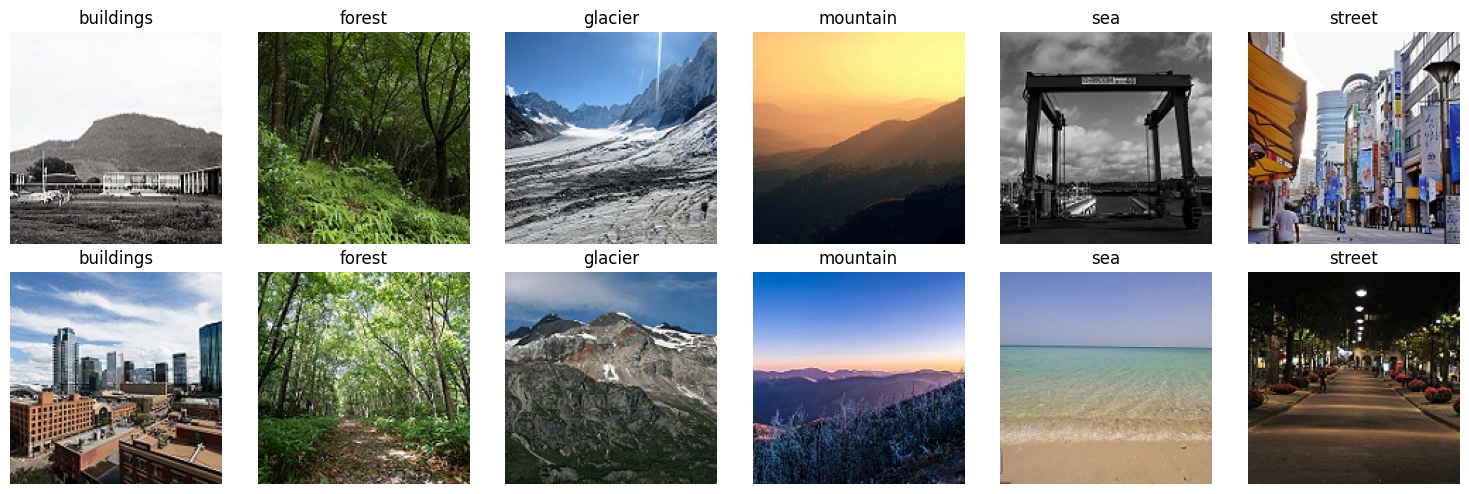

Sample image: 0.jpg
Shape (height, width, channels): (150, 150, 3)
Data type: uint8
Value range: 0 to 255
Top-left 3x3 values of the red channel:
[[247 247 248]
 [246 247 247]
 [246 246 247]]


In [4]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

fig, axes = plt.subplots(2, len(classes), figsize=(15, 5))

for column, class_name in enumerate(classes):
    image_files = sorted(
        path for path in (TRAIN_DIR / class_name).iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    )[:2]

    for row, image_path in enumerate(image_files):
        with Image.open(image_path) as image:
            axes[row, column].imshow(image.convert("RGB"))

        axes[row, column].set_title(class_name)
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

sample_path = next(
    path for path in (TRAIN_DIR / classes[0]).iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)

with Image.open(sample_path) as image:
    image_array = np.array(image.convert("RGB"))

print("Sample image:", sample_path.name)
print("Shape (height, width, channels):", image_array.shape)
print("Data type:", image_array.dtype)
print("Value range:", image_array.min(), "to", image_array.max())
print("Top-left 3x3 values of the red channel:")
print(image_array[:3, :3, 0])

### Part 1: Write it

The sample image is 150 × 150 pixels with three color channels. Its data type is `uint8`, and the pixel values range from 0 to 255.

From the image grid, glacier and mountain look most similar to me because both show rocky, high-altitude landscapes. Before training, I predict the model will confuse glacier and mountain most often. I’ll check this prediction against the confusion matrix in Part 6.

## Part 2: Convolution and Parameter Counts

In this part, I will apply a small edge-detection kernel to a simple image and a real photo. I will also compare the number of parameters in a convolutional layer and a dense layer.

Convolution output:
tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


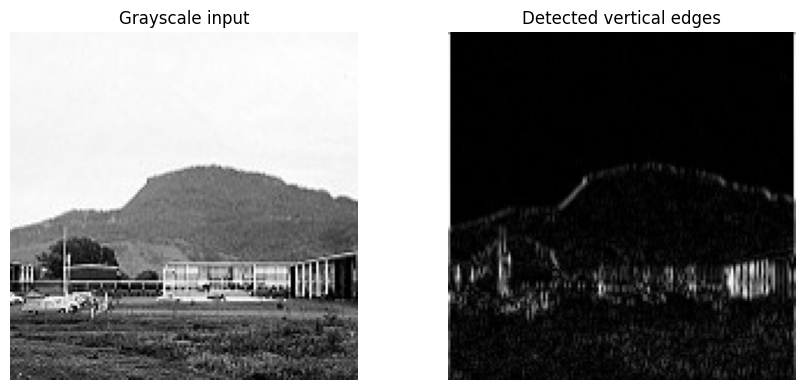

In [5]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image

# Apply a vertical-edge kernel to the lecture's 5x5 example.
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
kernel = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)

output = F.conv2d(
    x.view(1, 1, 5, 5),
    kernel.view(1, 1, 3, 3)
)

print("Convolution output:")
print(output.squeeze())

# Apply the same kernel to the sample photo.
image = Image.open(sample_path).convert("L")
gray_tensor = transforms.functional.to_tensor(image).unsqueeze(0)

edges = F.conv2d(
    gray_tensor,
    kernel.view(1, 1, 3, 3),
    padding=1
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(gray_tensor.squeeze(), cmap="gray")
axes[0].set_title("Grayscale input")
axes[1].imshow(edges.squeeze().abs().numpy(), cmap="gray")
axes[1].set_title("Detected vertical edges")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

### Task 2.2: Parameter Counts and Output Sizes

I will compare the number of parameters in a convolutional layer and a dense layer, then check how stride and pooling change the output size.

In [7]:
def count_parameters(layer):
    return sum(parameter.numel() for parameter in layer.parameters())

conv = torch.nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    padding=1
)

dense = torch.nn.Linear(150 * 150 * 3, 512)

print(f"Conv 3x3, 3 to 64: {count_parameters(conv):,} parameters")
print(f"Dense 67,500 to 512: {count_parameters(dense):,} parameters")

image_tensor = torch.randn(1, 3, 224, 224)

for stride in [1, 2]:
    layer = torch.nn.Conv2d(
        3, 64, kernel_size=3, stride=stride, padding=1
    )
    print(f"Stride {stride} output shape: {tuple(layer(image_tensor).shape)}")

print(
    "2x2 max-pool output shape:",
    tuple(torch.nn.functional.max_pool2d(image_tensor, 2).shape)
)

Conv 3x3, 3 to 64: 1,792 parameters
Dense 67,500 to 512: 34,560,512 parameters
Stride 1 output shape: (1, 64, 224, 224)
Stride 2 output shape: (1, 64, 112, 112)
2x2 max-pool output shape: (1, 3, 112, 112)


### Part 2: Write it

The convolution has `(3 × 3 × 3 + 1) × 64 = 1,792` parameters. The dense layer has `(150 × 150 × 3) × 512 + 512 = 34,560,512` parameters, which is 19,286 times as many.

A convolution shares the same filter weights across different image locations, instead of learning a separate set for every location. This lets it detect the same edge or pattern wherever it appears while using far fewer parameters.

## Part 3: Transforms and Data Loaders

ResNet-18 expects 224 × 224 images normalized with ImageNet’s mean and standard deviation. I will augment the training images, while keeping validation and test images unaugmented for fair evaluation.

In [8]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Use the same training images and split indices for both dataset views.
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

assert full_aug.class_to_idx == full_eval.class_to_idx == test_ds.class_to_idx

indices = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(indices))

train_ds = Subset(full_aug, indices[n_val:])
val_ds = Subset(full_eval, indices[:n_val])

train_dl = DataLoader(
    train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True
)
val_dl = DataLoader(
    val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True
)
test_dl = DataLoader(
    test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True
)

print("Classes:", full_aug.classes)
print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))
print("Batches — train:", len(train_dl), "| validation:", len(val_dl), "| test:", len(test_dl))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training images: 11929
Validation images: 2105
Test images: 3000
Batches — train: 187 | validation: 17 | test: 24


### Part 3: Write it

The data loaders contain 11,929 training images, 2,105 validation images, and 3,000 test images. I used augmentation only for training. Validation and test images are resized and normalized without random changes, so their evaluation stays consistent.

A vertical flip would be unsuitable for these scene images because it could turn the sky and ground upside down. A horizontal flip can be unsuitable for handwritten digits because it may create a mirrored shape that does not match the original label.

## Part 4: Training Loop and Feature Extraction

I will start with a ResNet-18 model pretrained on ImageNet. I will freeze its existing layers and train only a new output layer for the six scene classes.

In [9]:
import copy
import time
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = F.cross_entropy(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += len(labels)

    return total_loss / total, correct / total


def fit(model, optimizer, epochs, history):
    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        start_time = time.time()

        train_loss, train_accuracy = run_epoch(model, train_dl, optimizer)
        val_loss, val_accuracy = run_epoch(model, val_dl)

        history.append((train_loss, val_loss, train_accuracy, val_accuracy))

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start_time
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"train loss {train_loss:.3f}, accuracy {train_accuracy:.3f} | "
            f"validation loss {val_loss:.3f}, accuracy {val_accuracy:.3f} | "
            f"{elapsed:.0f}s"
        )

    model.load_state_dict(best_state)
    return best_accuracy

### Task 4.2: Freeze the body, train a new head
We download ResNet-18 with its ImageNet weights, then set `requires_grad = False` on every parameter, which freezes the whole pretrained network. Its last layer (`fc`) was built for ImageNet's 1,000 classes, so we replace it with a fresh `nn.Linear(512, 6)` for our six scenes. New layers are trainable by default, so this head is the only part that learns.

The trainable count should be **3,078**: 512 × 6 weights + 6 biases (slide 18), out of about 11.2 million in total. We train for 3 epochs with Adam at learning rate 1e-3. Each epoch takes roughly a minute on a T4.

📌 Write down the validation accuracy for each epoch. You need them for the write-up and the README.

In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the pretrained ResNet layers.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the 1,000-class ImageNet output with a 6-class output.
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

trainable = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)
total_parameters = sum(parameter.numel() for parameter in model.parameters())

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total_parameters:,}")

history = []
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

best_feature_accuracy = fit(
    model,
    optimizer,
    epochs=3,
    history=history
)

print(f"Best feature-extraction validation accuracy: {best_feature_accuracy:.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


Trainable parameters: 3,078
Total parameters: 11,179,590
Epoch 1/3 | train loss 0.592, accuracy 0.814 | validation loss 0.338, accuracy 0.894 | 502s
Epoch 2/3 | train loss 0.334, accuracy 0.882 | validation loss 0.309, accuracy 0.884 | 37s
Epoch 3/3 | train loss 0.296, accuracy 0.898 | validation loss 0.271, accuracy 0.906 | 36s
Best feature-extraction validation accuracy: 0.906


## Part 5: Fine-Tuning and Learning Curves

I will unfreeze ResNet-18’s final block and train it alongside the new output layer. The pretrained block will use a smaller learning rate so its learned features change more gradually.

In [14]:
# Unfreeze ResNet-18's final block.
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

trainable = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)
print(f"Trainable parameters after unfreezing layer4: {trainable:,}")

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
])

best_finetuned_accuracy = fit(
    model,
    optimizer,
    epochs=3,
    history=history
)

print(f"Best fine-tuned validation accuracy: {best_finetuned_accuracy:.3f}")

Trainable parameters after unfreezing layer4: 8,396,806
Epoch 1/3 | train loss 0.267, accuracy 0.906 | validation loss 0.218, accuracy 0.928 | 38s
Epoch 2/3 | train loss 0.165, accuracy 0.941 | validation loss 0.206, accuracy 0.936 | 38s
Epoch 3/3 | train loss 0.123, accuracy 0.956 | validation loss 0.248, accuracy 0.933 | 40s
Best fine-tuned validation accuracy: 0.936


In [16]:
for p in model.layer4.parameters():
    p.requires_grad = True                          # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
Epoch 1/3 | train loss 0.091, accuracy 0.966 | validation loss 0.233, accuracy 0.939 | 37s
Epoch 2/3 | train loss 0.068, accuracy 0.976 | validation loss 0.246, accuracy 0.937 | 37s
Epoch 3/3 | train loss 0.058, accuracy 0.979 | validation loss 0.301, accuracy 0.932 | 37s
Best validation accuracy, fine-tuned: 0.939


### Task 5.2: Learning Curves

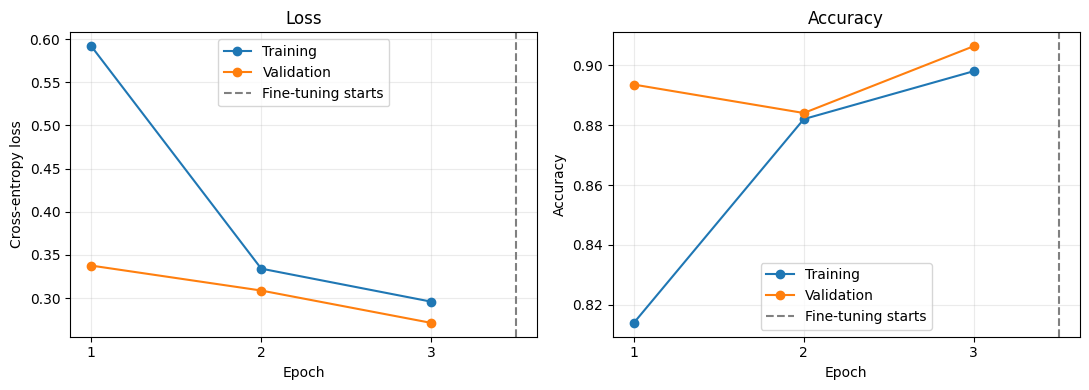

In [11]:
import matplotlib.pyplot as plt
import numpy as np

history_array = np.array(history)
epochs = np.arange(1, len(history_array) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, history_array[:, 0], "o-", label="Training")
axes[0].plot(epochs, history_array[:, 1], "o-", label="Validation")
axes[0].set_title("Loss")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(epochs, history_array[:, 2], "o-", label="Training")
axes[1].plot(epochs, history_array[:, 3], "o-", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_ylabel("Accuracy")

for axis in axes:
    axis.axvline(3.5, color="gray", linestyle="--", label="Fine-tuning starts")
    axis.set_xlabel("Epoch")
    axis.set_xticks(epochs)
    axis.legend()
    axis.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Part 6: Test Evaluation and Error Analysis

I will evaluate the selected model on the test set once, then inspect its class-level results and misclassified images.

Test accuracy: 0.901

Classification report:
              precision    recall  f1-score   support

   buildings      0.906     0.904     0.905       437
      forest      0.981     0.992     0.986       474
     glacier      0.885     0.776     0.827       553
    mountain      0.808     0.867     0.836       525
         sea      0.921     0.967     0.944       510
      street      0.916     0.918     0.917       501

    accuracy                          0.901      3000
   macro avg      0.903     0.904     0.903      3000
weighted avg      0.901     0.901     0.900      3000



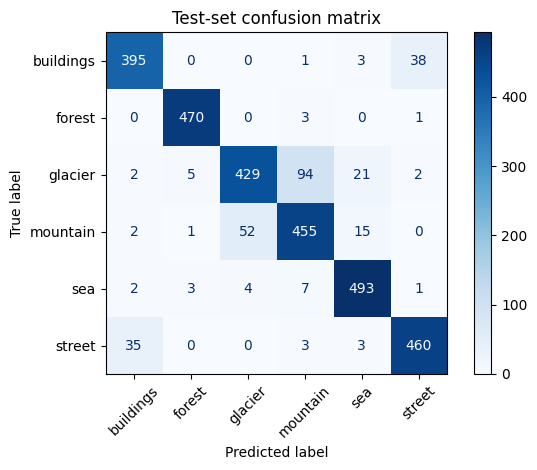


Recall by class:
buildings  0.904
forest     0.992
glacier    0.776
mountain   0.867
sea        0.967
street     0.918

Most confused direction: true glacier predicted as mountain (94 images)


In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model.eval()
all_probabilities = []
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels_batch in test_dl:
        images = images.to(device)
        logits = model(images)
        probabilities = F.softmax(logits, dim=1)

        all_probabilities.append(probabilities.cpu())
        all_predictions.append(probabilities.argmax(dim=1).cpu())
        all_labels.append(labels_batch.cpu())

probs = torch.cat(all_probabilities)
preds = torch.cat(all_predictions)
labels = torch.cat(all_labels)

test_accuracy = (preds == labels).float().mean().item()
print(f"Test accuracy: {test_accuracy:.3f}")

print("\nClassification report:")
print(classification_report(
    labels.numpy(),
    preds.numpy(),
    labels=list(range(len(classes))),
    target_names=classes,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(
    labels.numpy(),
    preds.numpy(),
    labels=list(range(len(classes)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
display.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

class_recall = np.divide(
    np.diag(cm),
    cm.sum(axis=1),
    out=np.zeros(len(classes), dtype=float),
    where=cm.sum(axis=1) != 0
)

print("\nRecall by class:")
for class_name, recall in zip(classes, class_recall):
    print(f"{class_name:10s} {recall:.3f}")

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)

if off_diagonal.max() > 0:
    true_idx, predicted_idx = np.unravel_index(
        off_diagonal.argmax(), off_diagonal.shape
    )
    print(
        "\nMost confused direction:",
        f"true {classes[true_idx]} predicted as {classes[predicted_idx]}",
        f"({off_diagonal[true_idx, predicted_idx]} images)"
    )

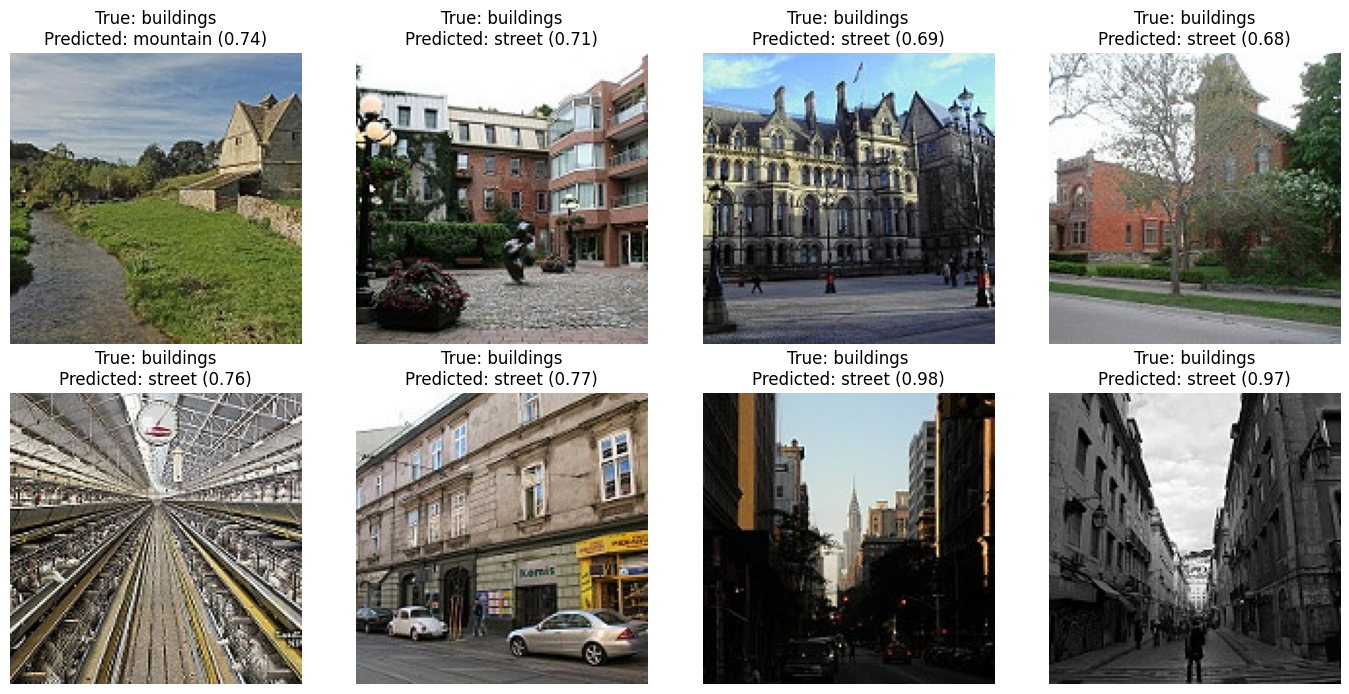

Displayed 8 misclassified images.


In [17]:
wrong_indices = torch.where(preds != labels)[0][:8].tolist()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis in axes.flat:
    axis.axis("off")

for axis, image_index in zip(axes.flat, wrong_indices):
    image_path, _ = test_ds.samples[image_index]

    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))

    true_label = classes[int(labels[image_index])]
    predicted_label = classes[int(preds[image_index])]
    confidence = float(probs[image_index].max())

    axis.set_title(
        f"True: {true_label}\nPredicted: {predicted_label} ({confidence:.2f})"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

print(f"Displayed {len(wrong_indices)} misclassified images.")

### Task 6.2: Error gallery
Numbers tell you how often the model is wrong. Pictures tell you **why**. This cell finds the first 8 test images the model got wrong and shows each one with its true label, the predicted label, and how confident the model was. A confident mistake (e.g. 0.95) is the most interesting kind: either the model learned something misleading, or the label itself is questionable.

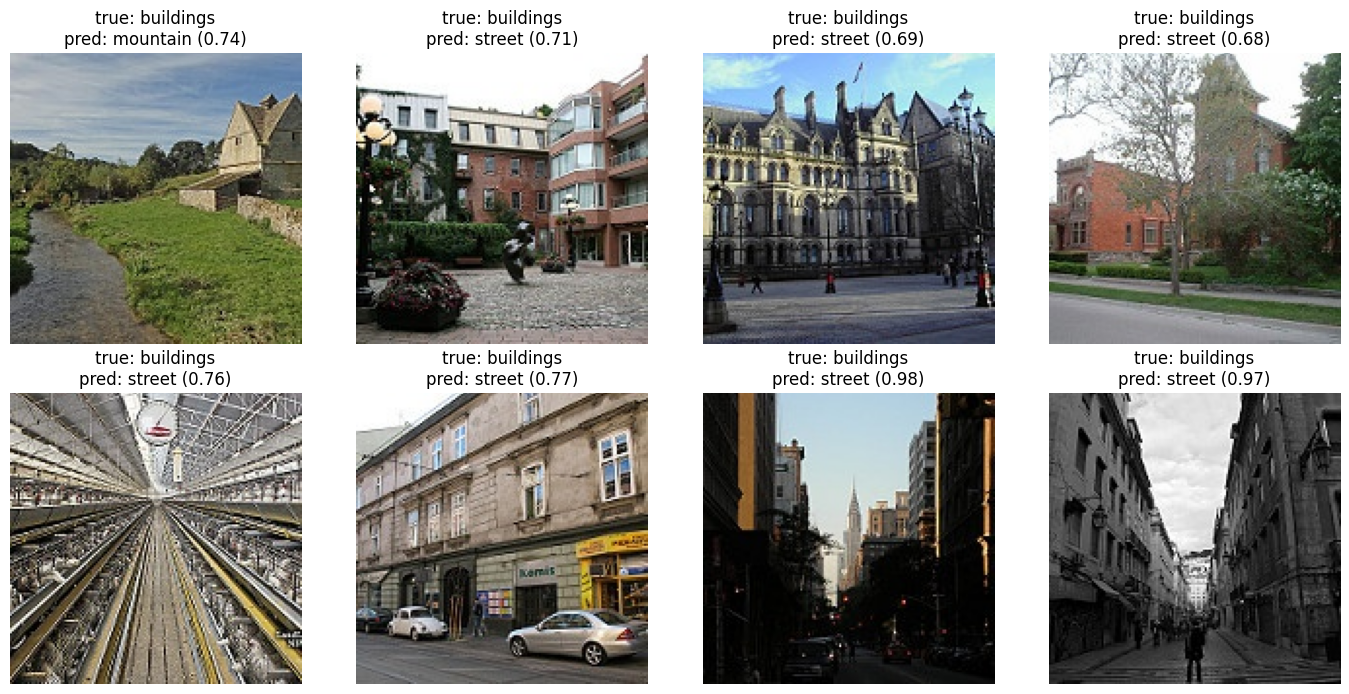

In [18]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

### Task 6.3: Inside one prediction
This opens up a single prediction for the first test image. It prints the six raw logits the network outputs, then the probabilities softmax turns them into. The probabilities are all positive and add up to 1, and the biggest logit gets the biggest probability. This is the same calculation as the forest / mountain / sea table on slide 10, just with six classes.

In [21]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')
print('Sum of probabilities:', round(p.sum().item(), 3))

True class: buildings
buildings  logit   9.92   probability 1.000
forest     logit -12.58   probability 0.000
glacier    logit  -6.80   probability 0.000
mountain   logit  -8.38   probability 0.000
sea        logit  -7.02   probability 0.000
street     logit  -1.31   probability 0.000
Sum of probabilities: 1.0


The model achieved 90.1% accuracy on the test set. Glacier was the hardest class, with a recall of 77.6%. The confusion matrix shows that 94 glacier images were predicted as mountains. These classes can look similar in some images, which may explain some of the confusion. In the error gallery, one example that stood out was [describe one image you saw and its incorrect prediction]. For the first test image, the true class and prediction were both buildings.

## Part 7: Save and Share

`state_dict()` holds every learned weight. Saving it means the model can be reloaded later without retraining (in Week 8 we serve a model like this through an API). The file is about 45 MB.

To reload it later, build the model the same way first (ResNet-18 **with the 6-class `fc` head**), then call `load_state_dict`. Otherwise you get a size-mismatch error.

In [22]:
from pathlib import Path
import torch

save_path = Path("/kaggle/working/resnet18_intel.pt")
torch.save(model.state_dict(), save_path)

print(f"Saved: {save_path}")
print(f"File size: {save_path.stat().st_size / (1024 * 1024):.1f} MB")

Saved: /kaggle/working/resnet18_intel.pt
File size: 42.7 MB


1. A linear layer transforms its input using weights and a bias. Stacking linear layers without nonlinear activations still produces one linear transformation: the output of one layer can be combined into the weights and bias of the next. So the network cannot learn more complex, nonlinear patterns.

2. Softmax is calculated as `exp(logit) / sum(exp(all logits))`.

   For the first class:

   `exp(3) / (exp(3) + exp(1) + exp(0)) ≈ 20.086 / (20.086 + 2.718 + 1) ≈ 0.844`

   The first class gets a probability of about **0.844**, or **84.4%**.

3. Assuming the convolution uses a bias:

   `parameters = (kernel height × kernel width × input channels + 1 bias) × output channels`

   `(3 × 3 × 64 + 1) × 128 = 73,856`

   The convolution has **73,856 parameters**.

4. The convolution output formula is:

   `output size = floor((input size + 2 × padding − kernel size) / stride) + 1`

   `floor((56 + 2 × 1 − 3) / 2) + 1 = 28`

   The output is **28 × 28**.

5. A residual block adds the input directly to the block’s output. This gives gradients a direct path backward through the network, helping them reach earlier layers instead of becoming too small as they pass through many layers.

6. Training from scratch can make sense when there is a large labeled dataset, enough computing power, and the images are very different from the data used to pretrain available models. Otherwise, transfer learning is often a practical starting point.